# Residuo del cono logarítmico y ceros de ζ — protocolo de robustez · **Versión 3 (enmienda)**

**Autor del estudio:** Rodrigo Pino Osorio · **Notebook reproducible** (numpy + matplotlib + mpmath, sin dependencias externas)

**Pregunta.** El residuo del cono, $R_v(i)=(p_{i+v}-p_i)-v\ln p_i$, analizado espectralmente en la variable $t=\ln p$
con peso $p^{-1/2}$, ¿muestra picos en las ordenadas $\gamma_n$ de los ceros no triviales de $\zeta(s)$, **más allá de lo que
produce el azar**?

**Qué NO afirma este notebook.** Que el fenómeno sea nuevo: la fórmula explícita de Riemann–von Mangoldt lo predice.
Lo que mide es si *esta* construcción (el residuo del cono) lo recupera de forma robusta frente a controles nulos.

**Estructura (E-D-T):** 0 · Criterios fijados antes de mirar → 1 · Primos (criba segmentada) → 2 · Ceros de ζ calculados
con mpmath → 3 · Espectro → 4 · Robustez en $v$ y ventanas → 5 · Controles nulos (Cramér y Cramér-mod-30) →
6 · Control positivo clásico → 7 · Veredicto automático contra los criterios → 8 · Exportación.

## CORRIDA CONFIRMATORIA (pre-registrada)

Código de v3 **congelado**. Solo cambian dos cosas: (1) el rango $\gamma\in[60,100]$, que no se examinó en v1–v3;
(2) el chequeo de mpmath ahora apunta a `zetazero(1)` en vez de `ZEROS[0]`, porque el primer cero del nuevo rango
ya no es 14.13. Predicciones, criterios y regla de decisión: ver `preregistro_confirmacion.md` (SHA-256 registrado
antes de ejecutar).

## Registro de enmiendas

### v2 → v3
| | |
|---|---|
| **Fecha** | 2026-10-12 · aprobada por R. Pino Osorio |
| **Motivo** | En v2 los 13 picos caían por debajo de su cero (Δ medio −0.0186; prueba de signo p = 2.4·10⁻⁴). El resultado se reprodujo idéntico en Colab. |
| **Diagnóstico** | 1) Se descartó la fuga espectral: con una señal sintética de 150 ceros sin primos, Δ medio = +0.001 y 6/13 negativos. 2) Causa: $R_v(i)$ mide el tramo $[p_i, p_{i+v}]$, pero v2 lo ubicaba en $t=\ln p_i$, el extremo izquierdo. Ese corrimiento depende de $t$, comprime el eje y baja los picos en proporción a $\gamma$. Prueba exploratoria a $10^9$ con $v=100$: izquierda −0.0186 (13/13 negativos) frente a centro +0.0017 (3/13). |
| **Cambios** | (1) **Convención**: $t=\ln\frac{p_i+p_{i+v}}{2}$, el centro del tramo. (2) **N_NULL = 99**: p-valor mínimo 0.01, ya no pegado al umbral 0.05. |
| **Sin cambios** | Definición del cono y del residuo; umbral dinámico $P_{\min}(v)$; peso $p_i^{-1/2}$; criterios (a), (b) y (c) con sus umbrales; modelos nulos; semillas; rango de $\gamma$; resolución y tolerancia. |
| **Advertencia** | El cambio de convención se probó de forma exploratoria antes de esta versión. La sección 3b reporta ambas convenciones para que el efecto quede a la vista. |

### v1 → v2

| | |
|---|---|
| **Fecha** | 2026-10-12 · aprobada por R. Pino Osorio |
| **Motivo** | v1 a $X=10^9$: veredicto NO CONCLUYENTE. Falló (a) por $v=1000$, mitad baja: 6/13; falló (c): deriva 0.289 > 0.273. |
| **Hipótesis** | Con $v$ grande y $p$ chico, el residuo promedia sobre un tramo $\Delta t\approx v\ln p/p$ en $t=\ln p$: es un filtro pasa-bajos de respuesta $\lvert\mathrm{sinc}(\gamma\Delta t/2)
vert$ que atenúa los $\gamma$ altos. Como el peso $p^{-1/2}$ favorece a los $p$ chicos, esa zona domina la suma. |
| **Cambio único** | Umbral dinámico: sólo se usan primos con $v\ln p/p<0.05$, es decir $p\ge P_{\min}(v)$. |
| **Sin cambios** | Criterios (a), (b) y (c) con sus umbrales; modelos nulos (Cramér y Cramér-mod-30); $N_{\text{nulos}}$; semillas; rango de $\gamma$; resolución y tolerancia definidas igual que en v1. |
| **Advertencia** | La enmienda se diseñó **después** de ver los datos de v1, así que su resultado es **exploratorio**, no confirmatorio. La sección 7b agrega anchos $v$ no usados en el diseño, solo como información. |
| **Límite conocido** | Justo en el umbral, $\gamma_{\max}\Delta t/2 = 60\cdot0.05/2 = 1.5$, y $\lvert\mathrm{sinc}
vert = 0.665$. La atenuación residual decae rápido al crecer $p$, pero no es cero. |

## 0 · Parámetros y criterios pre-registrados

Los criterios se fijan **aquí, antes de ejecutar nada**. El veredicto de la sección 7 se calcula contra ellos sin intervención.
Si cambias un criterio después de ver resultados, déjalo anotado (trazabilidad).

In [1]:
# ---------------- Parámetros de cómputo ----------------
X          = 10**9        # límite de la criba
P_MIN      = 10**4        # piso absoluto (igual que v1)
FILTRO_MAX = 0.05         # v2: condición v·ln(p)/p < FILTRO_MAX → P_MIN(v) dinámico
V_LIST     = [10, 100, 1000]   # anchos radiales del cono a probar
N_NULL     = 99           # v3: secuencias por modelo nulo. p-valor mínimo alcanzable = 1/(N_NULL+1) = 0.01
CONVENCION = "centro"     # v3: t = ln((p_i + p_{i+v})/2). "izquierda" reproduce v2 (t = ln p_i)
X_NULL     = 10**8        # escala del test contra nulos (real y nulos a la MISMA escala)
GAMMA_MIN, GAMMA_MAX, DGAMMA = 60.0, 100.0, 0.01   # CONFIRMACIÓN: rango de γ no examinado
DT_BIN     = 2e-4         # ancho de bin en t = ln p (error de fase ≤ GAMMA_MAX·DT_BIN/2 ≈ 0.006 rad)
SEED0      = 20261012

# ---------------- Criterios pre-registrados ----------------
CRITERIO = dict(
    aciertos_min_frac = 0.70,   # (a) ≥70 % de los ceros en [GAMMA_MIN, GAMMA_MAX] con pico emparejado, en TODAS las v y ventanas
    p_valor_max       = 0.05,   # (b) p-valor empírico < 0.05 frente a AMBOS modelos nulos (v=100, ventana completa)
    deriva_max_frac   = 0.5,    # (c) los picos emparejados no se mueven más de 0.5·resolución al cambiar v
)
assert 1/(N_NULL+1) < CRITERIO["p_valor_max"], "N_NULL demasiado chico: el p-valor nunca podría cumplir el criterio (b)"
assert X_NULL <= X

def p_min_for(v):
    # menor p ≥ P_MIN con v·ln(p)/p < FILTRO_MAX (la función es decreciente para p > e): bisección
    f = lambda p: v*math.log(p)/p - FILTRO_MAX
    lo, hi = 3.0, 1e15
    for _ in range(200):
        mid = (lo + hi)/2
        lo, hi = (mid, hi) if f(mid) >= 0 else (lo, mid)
    return max(P_MIN, int(math.ceil(hi)))

import math
for v in V_LIST:
    pm = p_min_for(v)
    print(f"  v={v:5d}: P_MIN(v) = {pm:>9,}   (v·ln p/p en el umbral = {v*math.log(pm)/pm:.4f})")
print("Parámetros y criterios fijados.")

  v=   10: P_MIN(v) =    10,000   (v·ln p/p en el umbral = 0.0092)
  v=  100: P_MIN(v) =    19,786   (v·ln p/p en el umbral = 0.0500)
  v= 1000: P_MIN(v) =   248,461   (v·ln p/p en el umbral = 0.0500)
Parámetros y criterios fijados.


## 1 · Primos hasta X — criba de Eratóstenes segmentada (implementación propia, memoria acotada)

In [2]:
import numpy as np, math, time, json, platform
import matplotlib.pyplot as plt

def base_primes(n):
    s = np.ones(n + 1, dtype=bool); s[:2] = False; s[4::2] = False
    for i in range(3, int(n**0.5) + 1, 2):
        if s[i]: s[i*i::2*i] = False
    return np.flatnonzero(s)

def segmented_primes(limit, seg=10**7):
    bp = base_primes(int(limit**0.5) + 1)
    out = [bp[bp <= limit].astype(np.uint32)]
    lo = int(bp[-1]) + 1
    while lo <= limit:
        hi = min(lo + seg, limit + 1)
        s = np.ones(hi - lo, dtype=bool)
        for p in bp:
            p = int(p)
            if p * p >= hi: break
            start = max(p * p, ((lo + p - 1) // p) * p)
            s[start - lo::p] = False
        out.append((np.flatnonzero(s) + lo).astype(np.uint32))
        lo = hi
    return np.concatenate(out)

t0 = time.time()
P = segmented_primes(X)
print(f"π({X:,}) = {len(P):,}  ·  {time.time()-t0:.1f} s  ·  {P.nbytes/1e6:.0f} MB")
# Verificación contra valores conocidos de π(x) (tabla clásica)
KNOWN = {10**4:1229, 10**5:9592, 10**6:78498, 10**7:664579, 10**8:5761455, 10**9:50847534}
for x, v in KNOWN.items():
    if x <= X:
        got = int(np.searchsorted(P, x, side='right'))
        assert got == v, f"π({x}) = {got} ≠ {v}"
        print(f"  ✔ π({x:,}) = {got:,}")

π(1,000,000,000) = 50,847,534  ·  14.7 s  ·  203 MB
  ✔ π(10,000) = 1,229


  ✔ π(100,000) = 9,592
  ✔ π(1,000,000) = 78,498


  ✔ π(10,000,000) = 664,579
  ✔ π(100,000,000) = 5,761,455


  ✔ π(1,000,000,000) = 50,847,534


## 2 · Ceros de ζ calculados de forma independiente (mpmath), no copiados de una tabla

In [3]:
import mpmath as mp
mp.mp.dps = 20
ZEROS = []
n = 1
while True:
    g = float(mp.zetazero(n).imag)
    if g > GAMMA_MAX: break
    if g >= GAMMA_MIN: ZEROS.append(g)
    n += 1
ZEROS = np.array(ZEROS)
assert abs(float(mp.zetazero(1).imag) - 14.134725142) < 1e-6   # chequeo de mpmath independiente del rango
print(f"{len(ZEROS)} ceros en [{GAMMA_MIN}, {GAMMA_MAX}]:", np.round(ZEROS, 4))

16 ceros en [60.0, 100.0]: [60.8318 65.1125 67.0798 69.5464 72.0672 75.7047 77.1448 79.3374 82.9104
 84.7355 87.4253 88.8091 92.4919 94.6513 95.8706 98.8312]


## 3 · Espectro del residuo

Para cada primo $p_i$ con $p_i\ge P_{\min}(v)$ (v2: $v\ln p_i/p_i<0.05$), ubicado en $t=\ln\frac{p_i+p_{i+v}}{2}$ (v3): $R_v(i)=(p_{i+v}-p_i)-v\ln p_i$. Se elimina la tendencia suave en $t$
(polinomio de grado 3), se pondera por $p^{-1/2}$, se acumula en bins uniformes de $t=\ln p$ y se evalúa
$A(\gamma)=\left|\sum_b w_b\,h(t_b)\,e^{-i\gamma t_b}\right|$ con ventana de Hann $h$ para reducir lóbulos laterales.
Resolución espectral ≈ $2\pi/\Delta t$.

Verificación FFT vs suma directa: error relativo máx = 7.79e-06
t ∈ [9.92, 20.72]  ·  resolución ≈ 0.581  ·  tolerancia de emparejamiento ±0.291
v=100: 16/16 ceros emparejados
   γ= 60.8318  →  pico  60.8222  (Δ=-0.010)
   γ= 65.1125  →  pico  65.1124  (Δ=-0.000)
   γ= 67.0798  →  pico  67.0832  (Δ=+0.003)
   γ= 69.5464  →  pico  69.5413  (Δ=-0.005)
   γ= 72.0672  →  pico  72.0647  (Δ=-0.002)
   γ= 75.7047  →  pico  75.7092  (Δ=+0.004)
   γ= 77.1448  →  pico  77.1244  (Δ=-0.020)
   γ= 79.3374  →  pico  79.3420  (Δ=+0.005)
   γ= 82.9104  →  pico  82.9252  (Δ=+0.015)
   γ= 84.7355  →  pico  84.7211  (Δ=-0.014)
   γ= 87.4253  →  pico  87.4205  (Δ=-0.005)
   γ= 88.8091  →  pico  88.8065  (Δ=-0.003)
   γ= 92.4919  →  pico  92.4883  (Δ=-0.004)
   γ= 94.6513  →  pico  94.7583  (Δ=+0.107)
   γ= 95.8706  →  pico  95.7875  (Δ=-0.083)
   γ= 98.8312  →  pico  98.8426  (Δ=+0.011)


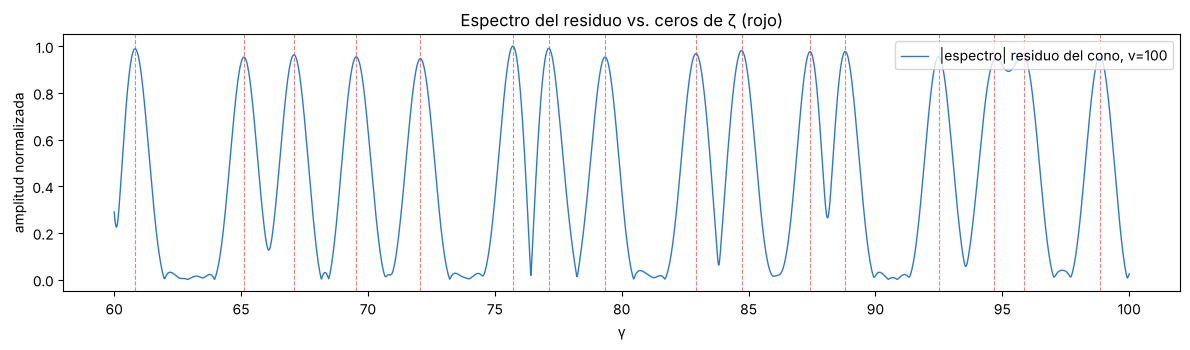

In [4]:
GAMMAS = np.arange(GAMMA_MIN, GAMMA_MAX + DGAMMA/2, DGAMMA)

CHUNK = 4_000_000   # memoria acotada: ~5 arreglos float64 de CHUNK elementos a la vez (~160 MB)

def _chunks(Q, v, tmin, tmax):
    i0 = int(np.searchsorted(Q, p_min_for(v))); n = len(Q) - v   # v2: umbral dinámico
    if i0 < n: assert v*math.log(float(Q[i0]))/float(Q[i0]) < FILTRO_MAX
    for a in range(i0, n, CHUNK):
        b = min(a + CHUNK, n)
        p = Q[a:b].astype(np.float64); q = Q[a+v:b+v].astype(np.float64)
        R = q - p - v*np.log(p)
        t = np.log(0.5*(p + q)) if CONVENCION == "centro" else np.log(p)   # v3: centro del tramo
        if tmin is not None:
            m = (t >= tmin) & (t < tmax)
            if not m.any(): continue
            p, R, t = p[m], R[m], t[m]
        yield p, R, t

def residual_bins(Q, v, tmin=None, tmax=None, deg=3):
    # Pasada 1: mínimos cuadrados exactos de R ~ polinomio(t) por ecuaciones normales acumuladas (centradas)
    tc = None
    for p, R, t in _chunks(Q, v, tmin, tmax):
        tc = t[0] if tc is None else tc
        tmax_seen = t[-1]
    t0c = (tc + tmax_seen) / 2; sc = (tmax_seen - tc) / 2
    XtX = np.zeros((deg+1, deg+1)); XtR = np.zeros(deg+1)
    for p, R, t in _chunks(Q, v, tmin, tmax):
        V = np.vander((t - t0c)/sc, deg+1); XtX += V.T @ V; XtR += V.T @ R
    coef = np.linalg.solve(XtX, XtR)
    # Pasada 2: residuo sin tendencia, peso p^{-1/2}, acumulado en bins de t
    nb = int((tmax_seen - tc) / DT_BIN) + 1
    wb = np.zeros(nb)
    for p, R, t in _chunks(Q, v, tmin, tmax):
        w = (R - np.vander((t - t0c)/sc, deg+1) @ coef) / np.sqrt(p)
        idx = np.minimum(((t - tc) / DT_BIN).astype(np.int64), nb - 1)
        wb += np.bincount(idx, weights=w, minlength=nb)
    tb = tc + (np.arange(nb) + 0.5) * DT_BIN
    return tb, wb

def spectrum_from_bins(tb, wb, signed=False):
    # Σ_b w_b h_b e^{-iγ t_b} vía FFT con relleno de ceros (bins uniformes en t), interpolado a GAMMAS.
    h = np.hanning(len(tb)); x = wb * h
    dt = tb[1] - tb[0]
    N = 1 << int(np.ceil(np.log2(max(len(x), 4 * 2*np.pi / (DGAMMA * dt)))))   # espaciado ≤ DGAMMA/4
    F = np.fft.rfft(x, N)                                  # Σ x_b e^{-i ω b},  ω = 2πk/N
    g = 2*np.pi*np.arange(len(F)) / (N * dt)               # γ_k
    z = F * np.exp(-1j * g * tb[0])                        # fase absoluta: e^{-iγ t_0}
    val = -z.real if signed else np.abs(z)
    return np.interp(GAMMAS, g, val)

def spectrum_direct(tb, wb, signed=False):   # referencia lenta, sólo para verificar la FFT
    h = np.hanning(len(tb)); wb = wb * h
    A = np.empty(len(GAMMAS))
    for k0 in range(0, len(GAMMAS), 200):
        gg = GAMMAS[k0:k0+200, None]
        z = (wb[None, :] * np.exp(-1j * gg * tb[None, :])).sum(1)
        A[k0:k0+200] = -z.real if signed else np.abs(z)
    return A

def resolution(tb): return 2*np.pi / (tb[-1] - tb[0])

def peak_match(A, res):
    # picos locales ordenados por altura; se toman tantos como ceros hay en el rango
    loc = np.flatnonzero((A[1:-1] > A[:-2]) & (A[1:-1] > A[2:])) + 1
    loc = loc[np.argsort(A[loc])[::-1]][:len(ZEROS)]
    # interpolación parabólica para posición sub-grilla
    pk = []
    for j in loc:
        y0, y1, y2 = A[j-1], A[j], A[j+1]; d = 0.5*(y0 - y2)/(y0 - 2*y1 + y2)
        pk.append(GAMMAS[j] + d*DGAMMA)
    pk = np.array(sorted(pk))
    tol = 0.5 * res
    matched = {}
    for z in ZEROS:
        if len(pk) == 0: break
        k = np.argmin(np.abs(pk - z))
        if abs(pk[k] - z) <= tol: matched[float(z)] = float(pk[k])
    return pk, matched, tol

tb, wb = residual_bins(P, 100)
A100 = spectrum_from_bins(tb, wb)
# Verificación: FFT vs suma directa en una submuestra de γ (deben coincidir)
_sel = slice(0, len(GAMMAS), 97); _G = GAMMAS
GAMMAS = _G[_sel]; _Ad = spectrum_direct(tb, wb); GAMMAS = _G
_err = np.max(np.abs(A100[_sel] - _Ad)) / np.max(_Ad)
print(f"Verificación FFT vs suma directa: error relativo máx = {_err:.2e}"); assert _err < 1e-3
RES = resolution(tb)
pk, matched, tol = peak_match(A100, RES)
print(f"t ∈ [{tb[0]:.2f}, {tb[-1]:.2f}]  ·  resolución ≈ {RES:.3f}  ·  tolerancia de emparejamiento ±{tol:.3f}")
print(f"v=100: {len(matched)}/{len(ZEROS)} ceros emparejados")
for z in ZEROS:
    m = matched.get(float(z)); print(f"   γ={z:8.4f}  →  " + (f"pico {m:8.4f}  (Δ={m-z:+.3f})" if m else "—"))

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(GAMMAS, A100/A100.max(), lw=1, color="#2a78d6", label="|espectro| residuo del cono, v=100")
for z in ZEROS: ax.axvline(z, color="#e34948", lw=0.8, ls="--", alpha=0.7)
ax.set_xlabel("γ"); ax.set_ylabel("amplitud normalizada"); ax.set_title("Espectro del residuo vs. ceros de ζ (rojo)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

### 3b · ¿Los picos están desplazados sistemáticamente? (se reportan ambas convenciones)
Prueba de signo binomial, dos colas, sobre Δ = pico − γ con $v=100$. **Predicción de v3**: con la convención del centro,
no debe haber sesgo de signo (p ≥ 0.05). La convención izquierda (v2) se recalcula aquí solo para comparar.

In [5]:
from math import comb
def sign_test(m):
    D = np.array([m[float(z)] - z for z in ZEROS if float(z) in m])
    n_neg, n = int((D < 0).sum()), len(D); k = min(n_neg, n - n_neg)
    p = min(1.0, 2*sum(comb(n, i) for i in range(k+1)) / 2**n) if n else float('nan')
    return D, n_neg, n, p

D, n_neg, n, p_sign = sign_test(matched)
_conv = CONVENCION; CONVENCION = "izquierda"
tbL, wbL = residual_bins(P, 100); _, matched_L, _ = peak_match(spectrum_from_bins(tbL, wbL), resolution(tbL))
CONVENCION = _conv
D_L, n_neg_L, n_L, p_sign_L = sign_test(matched_L)
print(f"centro    (v3): Δ medio = {D.mean():+.4f}  ·  negativos {n_neg}/{n}  ·  p signo = {p_sign:.3g}  ·  |Δ| máx = {np.abs(D).max():.3f}")
print(f"izquierda (v2): Δ medio = {D_L.mean():+.4f}  ·  negativos {n_neg_L}/{n_L}  ·  p signo = {p_sign_L:.3g}")
print("→ predicción de v3 CUMPLIDA: sin sesgo de signo" if p_sign >= 0.05 else "→ predicción de v3 NO cumplida: persiste un sesgo")

centro    (v3): Δ medio = -0.0000  ·  negativos 10/16  ·  p signo = 0.454  ·  |Δ| máx = 0.107
izquierda (v2): Δ medio = -0.0375  ·  negativos 15/16  ·  p signo = 0.000519
→ predicción de v3 CUMPLIDA: sin sesgo de signo


## 4 · Robustez: distintos anchos $v$ y distintas ventanas de $\ln p$

In [6]:
# v2: cada v usa su propio rango válido [ln P_MIN(v), ln X]; las mitades se definen sobre ese rango.
ROB = []
peaks_by_v = {}
for v in V_LIST:
    tfull, _ = residual_bins(P, v)
    tlo, thi = tfull[0], tfull[-1]; mid = (tlo + thi)/2
    WINDOWS = {"completa": (None, None), "mitad baja": (tlo, mid), "mitad alta": (mid, thi + DT_BIN)}
    for wname, (a, b) in WINDOWS.items():
        tbv, wbv = residual_bins(P, v, a, b)
        A = spectrum_from_bins(tbv, wbv); r = resolution(tbv)
        pkv, mv, tolv = peak_match(A, r)
        ROB.append(dict(v=v, ventana=wname, t=[round(float(tbv[0]),3), round(float(tbv[-1]),3)],
                        resolucion=round(r,3), aciertos=len(mv), total=len(ZEROS)))
        if wname == "completa": peaks_by_v[v] = mv
        print(f"v={v:5d}  {wname:10s}  t∈[{tbv[0]:5.2f},{tbv[-1]:5.2f}]  res={r:.3f}  aciertos {len(mv):2d}/{len(ZEROS)}")

# deriva de picos entre v (sólo ventana completa)
drift = []
for z in ZEROS:
    vals = [peaks_by_v[v].get(float(z)) for v in V_LIST]
    if all(x is not None for x in vals): drift.append(max(vals) - min(vals))
DRIFT_MAX = max(drift) if drift else float('nan')
print(f"\nDeriva máxima de un pico emparejado entre v={V_LIST}: {DRIFT_MAX:.3f}  (límite {CRITERIO['deriva_max_frac']}·res = {CRITERIO['deriva_max_frac']*RES:.3f})")

v=   10  completa    t∈[ 9.22,20.72]  res=0.546  aciertos 16/16


v=   10  mitad baja  t∈[ 9.22,14.97]  res=1.092  aciertos 13/16


v=   10  mitad alta  t∈[14.97,20.72]  res=1.092  aciertos 10/16


v=  100  completa    t∈[ 9.92,20.72]  res=0.581  aciertos 16/16


v=  100  mitad baja  t∈[ 9.92,15.32]  res=1.163  aciertos  9/16


v=  100  mitad alta  t∈[15.32,20.72]  res=1.163  aciertos 10/16


v= 1000  completa    t∈[12.45,20.72]  res=0.759  aciertos 16/16


v= 1000  mitad baja  t∈[12.45,16.59]  res=1.519  aciertos  6/16


v= 1000  mitad alta  t∈[16.59,20.72]  res=1.519  aciertos 11/16

Deriva máxima de un pico emparejado entre v=[10, 100, 1000]: 0.234  (límite 0.5·res = 0.291)


## 5 · Controles nulos

Mismo pipeline, idénticos parámetros, sobre secuencias **sin** ceros de ζ detrás:

* **Cramér**: cada impar $n$ se incluye con probabilidad $2/\ln n$.
* **Cramér-mod-30**: sólo $n$ coprimos con 30, probabilidad $\tfrac{30}{8}/\ln n$ (respeta la retícula: descarta que los picos vengan de ella).

p-valor empírico $=(1+\#\{\text{nulos con} \ge \text{aciertos reales}\})/(1+N)$.

In [7]:
def cramer(limit, rng, mod30=False, seg=10**7):   # v2: segmento 1e7 → pico de RAM menor
    out = [np.array([2, 3, 5], dtype=np.uint32)] if mod30 else [np.array([2], dtype=np.uint32)]
    res30 = np.array([1, 7, 11, 13, 17, 19, 23, 29])
    lo = 7
    while lo <= limit:
        hi = min(lo + seg, limit + 1)
        if mod30:
            base = np.arange((lo//30)*30, hi, 30)
            n = (base[:, None] + res30[None, :]).ravel(); n = n[(n >= lo) & (n < hi)]
            prob = (30/8) / np.log(n)
        else:
            n = np.arange(lo | 1, hi, 2); prob = 2 / np.log(n)
        out.append(n[rng.random(len(n)) < prob].astype(np.uint32)); lo = hi
    return np.concatenate(out)

# real y nulos a la misma escala X_NULL (comparación justa)
P_test = P[P <= X_NULL]
tr, wr = residual_bins(P_test, 100)
_, matched_test, _ = peak_match(spectrum_from_bins(tr, wr), resolution(tr))
real_hits = len(matched_test)
print(f"Real a X_NULL={X_NULL:,}: {real_hits}/{len(ZEROS)} aciertos")
NULL = {"Cramér": [], "Cramér-mod-30": []}
t0 = time.time()
for k in range(N_NULL):
    for name, m30 in (("Cramér", False), ("Cramér-mod-30", True)):
        rng = np.random.default_rng(SEED0 + 1000*k + int(m30))
        Q = cramer(X_NULL, rng, mod30=m30)
        tq, wq = residual_bins(Q, 100)
        _, mq, _ = peak_match(spectrum_from_bins(tq, wq), resolution(tq))
        NULL[name].append(len(mq)); del Q
    print(f"  nulo {k+1}/{N_NULL}  ·  {time.time()-t0:.0f} s  ·  Cramér={NULL['Cramér'][-1]}  mod30={NULL['Cramér-mod-30'][-1]}")

PVAL = {name: (1 + sum(h >= real_hits for h in hs)) / (1 + len(hs)) for name, hs in NULL.items()}
ZSC = {}
for name, hs in NULL.items():
    sd = np.std(hs, ddof=1) if len(hs) > 1 else float('nan')
    ZSC[name] = (real_hits - np.mean(hs)) / sd if sd and sd > 0 else float('inf')
    print(f"{name:14s}: aciertos nulos media={np.mean(hs):.2f} máx={max(hs)}  ·  real={real_hits}  ·  p-valor={PVAL[name]:.4f}  ·  z={ZSC[name]:.1f}")

Real a X_NULL=100,000,000: 16/16 aciertos


  nulo 1/99  ·  8 s  ·  Cramér=4  mod30=3


  nulo 2/99  ·  15 s  ·  Cramér=6  mod30=8


  nulo 3/99  ·  22 s  ·  Cramér=6  mod30=6


  nulo 4/99  ·  30 s  ·  Cramér=10  mod30=3


...

  nulo 95/99  ·  768 s  ·  Cramér=4  mod30=8


  nulo 96/99  ·  775 s  ·  Cramér=5  mod30=4


  nulo 97/99  ·  783 s  ·  Cramér=2  mod30=5


  nulo 98/99  ·  791 s  ·  Cramér=8  mod30=6


  nulo 99/99  ·  799 s  ·  Cramér=7  mod30=7
Cramér        : aciertos nulos media=5.09 máx=10  ·  real=16  ·  p-valor=0.0100  ·  z=6.4
Cramér-mod-30 : aciertos nulos media=4.86 máx=8  ·  real=16  ·  p-valor=0.0100  ·  z=6.6


## 6 · Control positivo clásico

Suma sobre potencias de primos $\sum_{p^k\le X}\ln p\;p^{-k/2}\cos(\gamma\,k\ln p)$: su parte negativa marca los ceros
(fórmula explícita). Si este control **no** acertara, el problema sería del pipeline, no del residuo.

In [8]:
tmin_c = math.log(2.0); nb_c = int((math.log(X) - tmin_c) / DT_BIN) + 2
wb_c = np.zeros(nb_c)
for a in range(0, len(P), CHUNK):
    pf = P[a:a+CHUNK].astype(np.float64); lp = np.log(pf)
    for k in (1, 2, 3):
        m = pf**k <= X
        if not m.any(): break
        tk = k*lp[m]; wk = lp[m] / pf[m]**(k/2)
        wb_c += np.bincount(((tk - tmin_c)/DT_BIN).astype(np.int64), weights=wk, minlength=nb_c)
tb_c = tmin_c + (np.arange(nb_c) + 0.5)*DT_BIN
A_c = spectrum_from_bins(tb_c, wb_c, signed=True)
_, matched_c, _ = peak_match(A_c, resolution(tb_c))
print(f"Control positivo: {len(matched_c)}/{len(ZEROS)} ceros emparejados")

Control positivo: 16/16 ceros emparejados


## 7 · Veredicto automático contra los criterios pre-registrados

In [9]:
frac_min = min(r["aciertos"]/r["total"] for r in ROB)
ok_a = frac_min >= CRITERIO["aciertos_min_frac"]
ok_b = all(p < CRITERIO["p_valor_max"] for p in PVAL.values())
ok_c = DRIFT_MAX <= CRITERIO["deriva_max_frac"]*RES
print(f"(a) aciertos mínimos en todas las v/ventanas: {frac_min:.0%}  (≥ {CRITERIO['aciertos_min_frac']:.0%})  →  {'CUMPLE' if ok_a else 'NO CUMPLE'}")
print(f"(b) p-valores {dict((k, round(v,4)) for k,v in PVAL.items())}  (< {CRITERIO['p_valor_max']})  →  {'CUMPLE' if ok_b else 'NO CUMPLE'}")
print(f"(c) deriva máxima entre v: {DRIFT_MAX:.3f}  (≤ {CRITERIO['deriva_max_frac']*RES:.3f})  →  {'CUMPLE' if ok_c else 'NO CUMPLE'}")
print(f"Control positivo: {len(matched_c)}/{len(ZEROS)}")
VEREDICTO = "SEÑAL ROBUSTA" if (ok_a and ok_b and ok_c) else "NO CONCLUYENTE"
print("\nVEREDICTO:", VEREDICTO)

(a) aciertos mínimos en todas las v/ventanas: 38%  (≥ 70%)  →  NO CUMPLE
(b) p-valores {'Cramér': 0.01, 'Cramér-mod-30': 0.01}  (< 0.05)  →  CUMPLE
(c) deriva máxima entre v: 0.234  (≤ 0.291)  →  CUMPLE
Control positivo: 16/16

VEREDICTO: NO CONCLUYENTE


## 7b · Información adicional (NO entra en el veredicto)

1. **Anchos $v$ no usados al diseñar la enmienda** ($v$ = 30 y 300), con la misma regla.
2. **Sensibilidad con rango común**: todas las $v$ sobre el mismo tramo $[\ln P_{\min}(v_{\max}),\ln X]$. Así la deriva entre $v$ no mezcla resoluciones distintas.
3. **Memoria**: pico de RAM del proceso, medido.

In [10]:
INFO = {}
for v in (30, 300):
    tq, wq = residual_bins(P, v); _, mq, _ = peak_match(spectrum_from_bins(tq, wq), resolution(tq))
    INFO[f"v={v}"] = f"{len(mq)}/{len(ZEROS)}"
    print(f"v={v:4d} (no visto): {len(mq)}/{len(ZEROS)} aciertos · P_MIN(v)={p_min_for(v):,}")

t_common = math.log(p_min_for(max(V_LIST)))
pk_common = {}
for v in V_LIST:
    tq, wq = residual_bins(P, v, t_common, math.log(X) + 1)
    rq = resolution(tq); _, mq, _ = peak_match(spectrum_from_bins(tq, wq), rq)
    pk_common[v] = mq
    print(f"rango común t∈[{tq[0]:.2f},{tq[-1]:.2f}]  v={v:5d}: {len(mq)}/{len(ZEROS)}  res={rq:.3f}")
dc = [max(x) - min(x) for z in ZEROS
      for x in [[pk_common[v].get(float(z)) for v in V_LIST]] if all(y is not None for y in x)]
INFO["deriva_rango_comun"] = float(max(dc)) if dc else None
INFO["res_rango_comun"] = float(rq)
print(f"deriva máx. con rango común: {INFO['deriva_rango_comun']:.3f}  (0.5·res común = {0.5*rq:.3f})")

import resource
RAM_PICO_MB = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
INFO["ram_pico_MB"] = round(RAM_PICO_MB)
print(f"RAM pico del proceso: {RAM_PICO_MB:,.0f} MB")

v=  30 (no visto): 16/16 aciertos · P_MIN(v)=10,000


v= 300 (no visto): 15/16 aciertos · P_MIN(v)=66,643


rango común t∈[12.42,20.72]  v=   10: 16/16  res=0.757


rango común t∈[12.42,20.72]  v=  100: 16/16  res=0.757


rango común t∈[12.45,20.72]  v= 1000: 16/16  res=0.759
deriva máx. con rango común: 0.038  (0.5·res común = 0.380)
RAM pico del proceso: 1,100 MB


## 8 · Exportación (JSON con todo lo necesario para auditar)

In [11]:
OUT = dict(
    version="v3", enmienda=dict(FILTRO_MAX=FILTRO_MAX, P_MIN_v={v: p_min_for(v) for v in V_LIST}, CONVENCION=CONVENCION),
    sesgo=dict(centro=dict(delta_medio=float(D.mean()), negativos=n_neg, n=n, p_signo=p_sign),
               izquierda=dict(delta_medio=float(D_L.mean()), negativos=n_neg_L, n=n_L, p_signo=p_sign_L)),
    info_no_veredicto=INFO,
    meta=dict(X=X, P_MIN=P_MIN, n_primos=int(len(P)), V_LIST=V_LIST, N_NULL=N_NULL, DT_BIN=DT_BIN, SEED0=SEED0,
              gamma=[GAMMA_MIN, GAMMA_MAX, DGAMMA], numpy=np.__version__, python=platform.python_version()),
    criterios=CRITERIO, ceros=ZEROS.tolist(), resolucion=RES,
    v100=dict(emparejados=matched, delta_medio=float(D.mean()), p_signo=p_sign), robustez=ROB, deriva_max=DRIFT_MAX,
    X_NULL=X_NULL, real_a_X_NULL=real_hits, nulos=NULL, p_valores=PVAL, z=ZSC, control_positivo=len(matched_c), veredicto=VEREDICTO)
with open("resultados_confirmacion.json", "w", encoding="utf-8") as f: json.dump(OUT, f, ensure_ascii=False, indent=2)
print("Guardado resultados_confirmacion.json")
try:
    from google.colab import files; files.download("resultados_confirmacion.json")
except Exception:
    pass

Guardado resultados_confirmacion.json
